# Experiments 6,7,8
## Date: 20-11-2026

# 6.Logistic Regression for Customer Churn Prediction

Telecom Customer Churn Prediction using Logistic Regression
 tenure_months  monthly_bill  complaints  yearly_contract  churn
            25         451.0           0                1      0
             4        1144.0           2                0      1
            57         907.0           0                1      0
             1         895.0           3                1      1
            22         804.0           2                0      1

Churn distribution: {0: 275, 1: 125}

Coefficients (standardised features):
  tenure_months     -0.9840   odds ratio = 0.374
  monthly_bill       0.5947   odds ratio = 1.813
  complaints         0.8709   odds ratio = 2.389
  yearly_contract   -0.3921   odds ratio = 0.676
  Intercept         -1.0823

Validation on test set:
  Accuracy  = 0.7600
  Precision = 0.7333
  Recall    = 0.3548
  F1-score  = 0.4783
  ROC-AUC   = 0.8401

Confusion Matrix [rows = actual, cols = predicted]:
[[65  4]
 [20 11]]

5-fold cross-validation accuracy: [0.8125 0.82

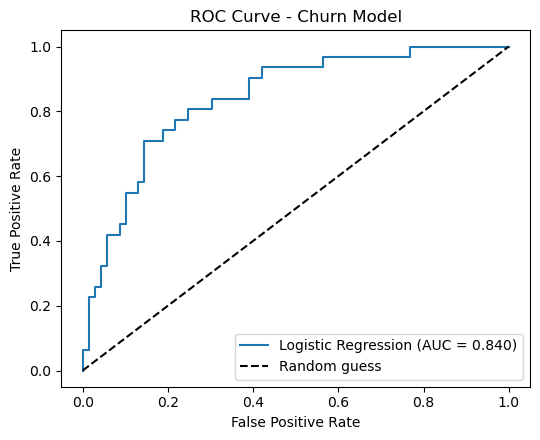

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import train_test_split, cross_val_score 
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import make_pipeline 
from sklearn.metrics import ( 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve, 
) 
  
np.random.seed(3) 
n = 400 
tenure = np.random.randint(1, 72, n) 
monthly = np.round(np.random.uniform(200, 1500, n), 0) 
complaints = np.random.poisson(1.2, n) 
contract = np.random.choice([0, 1], n, p=[0.55, 0.45])  # 1 = yearly contract 
logit = -1.0 - 0.06 * tenure + 0.002 * monthly + 0.7 * complaints - 1.3 * contract 
churn = (np.random.rand(n) < 1 / (1 + np.exp(-logit))).astype(int) 
data = pd.DataFrame( 
    { 
        "tenure_months": tenure, 
        "monthly_bill": monthly, 
        "complaints": complaints, 
        "yearly_contract": contract, 
        "churn": churn, 
    } 
) 
  
print("Telecom Customer Churn Prediction using Logistic Regression") 
print("=" * 60) 
print(data.head().to_string(index=False)) 
print("\nChurn distribution:", data["churn"].value_counts().to_dict()) 
  
X = data.drop(columns="churn") 
y = data["churn"] 
X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.25, stratify=y, random_state=0 
) 
  
model = make_pipeline(StandardScaler(), LogisticRegression()) 
model.fit(X_train, y_train) 
lr = model.named_steps["logisticregression"] 
print("\nCoefficients (standardised features):") 
for name, c in zip(X.columns, lr.coef_[0]): 
    print(f"  {name:<16} {c:>8.4f}   odds ratio = {np.exp(c):.3f}") 
print(f"  {'Intercept':<16} {lr.intercept_[0]:>8.4f}") 
  
pred = model.predict(X_test) 
prob = model.predict_proba(X_test)[:, 1] 
print("\nValidation on test set:") 
print(f"  Accuracy  = {accuracy_score(y_test, pred):.4f}") 
print(f"  Precision = {precision_score(y_test, pred):.4f}") 
print(f"  Recall    = {recall_score(y_test, pred):.4f}") 
print(f"  F1-score  = {f1_score(y_test, pred):.4f}") 
print(f"  ROC-AUC   = {roc_auc_score(y_test, prob):.4f}") 
print("\nConfusion Matrix [rows = actual, cols = predicted]:") 
print(confusion_matrix(y_test, pred)) 
  
cv = cross_val_score(model, X, y, cv=5, scoring="accuracy") 
print("\n5-fold cross-validation accuracy:", np.round(cv, 4)) 
print(f"Mean = {cv.mean():.4f}, Std = {cv.std():.4f}") 
  
customer = pd.DataFrame([[4, 1250, 3, 0]], columns=X.columns) 
p = model.predict_proba(customer)[0, 1] 
print( 
    "\nNew customer (4 months, Rs.1250, 3 complaints, monthly plan):", 
    f"churn probability = {p:.3f}", 
) 
  
fpr, tpr, _ = roc_curve(y_test, prob) 
plt.figure(figsize=(5.5, 4.5)) 
plt.plot( 
    fpr, 
    tpr, 
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, prob):.3f})", 
) 
plt.plot([0, 1], [0, 1], "k--", label="Random guess") 
plt.xlabel("False Positive Rate") 
plt.ylabel("True Positive Rate") 
plt.title("ROC Curve - Churn Model") 
plt.legend() 
plt.tight_layout() 
plt.savefig("exp06_roc.png", dpi=150) 
plt.show()

# 7.Naive Bayes and Memorization Methods for Classification

In [2]:
import numpy as np 
import pandas as pd 
from sklearn.datasets import load_wine 
from sklearn.model_selection import ( 
    train_test_split, 
    cross_val_score, 
    StratifiedKFold, 
) 
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import make_pipeline 
from sklearn.naive_bayes import GaussianNB 
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.tree import DecisionTreeClassifier, export_text 
from sklearn.metrics import ( 
    accuracy_score, 
    classification_report, 
    confusion_matrix, 
) 
  
wine = load_wine() 
X = pd.DataFrame(wine.data, columns=wine.feature_names) 
y = wine.target 
  
print("Wine Quality Classification: Naive Bayes vs Memorization Methods") 
print("=" * 65) 
print( 
    "Samples:", 
    X.shape[0], 
    "| Features:", 
    X.shape[1], 
    "| Classes:", 
    list(wine.target_names), 
) 
print("Class counts:", np.bincount(y).tolist()) 
  
X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.3, stratify=y, random_state=42 
) 
  
models = { 
    "Gaussian Naive Bayes": GaussianNB(), 
    "k-Nearest Neighbours (k=5)": make_pipeline( 
        StandardScaler(), KNeighborsClassifier(n_neighbors=5) 
    ), 
    "Decision Tree (depth=3)": DecisionTreeClassifier( 
        max_depth=3, random_state=42 
    ), 
} 
  
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 
summary = [] 
for name, model in models.items(): 
    model.fit(X_train, y_train) 
    train_acc = accuracy_score(y_train, model.predict(X_train)) 
    test_acc = accuracy_score(y_test, model.predict(X_test)) 
    cv = cross_val_score(model, X, y, cv=kfold) 
    summary.append([name, train_acc, test_acc, cv.mean(), cv.std()]) 
  
table = pd.DataFrame( 
    summary, columns=["Model", "Train Acc", "Test Acc", "CV Mean", "CV Std"] 
) 
print("\nModel comparison:") 
print(table.round(4).to_string(index=False)) 
  
best = table.sort_values(["CV Mean", "Test Acc"], ascending=False).iloc[0][ 
    "Model" 
] 
print("\nSelected model (highest CV accuracy):", best) 
pred = models[best].predict(X_test) 
print("\nConfusion matrix of selected model:") 
print(confusion_matrix(y_test, pred)) 
print("\nClassification report:") 
print(classification_report(y_test, pred, target_names=wine.target_names)) 
  
# ---------- Effect of k in kNN (memorization) ---------- 
print("Effect of k on kNN (5-fold CV accuracy):") 
for k in [1, 3, 5, 7, 11, 15]: 
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)) 
    print(f"  k = {k:>2}  ->  {cross_val_score(knn, X, y, cv=kfold).mean():.4f}") 
  
# ---------- Rules learnt by the decision tree ---------- 
print("\nDecision tree rules:") 
print( 
    export_text(models["Decision Tree (depth=3)"], feature_names=list(X.columns)) 
) 

Wine Quality Classification: Naive Bayes vs Memorization Methods
Samples: 178 | Features: 13 | Classes: ['class_0', 'class_1', 'class_2']
Class counts: [59, 71, 48]

Model comparison:
                     Model  Train Acc  Test Acc  CV Mean  CV Std
      Gaussian Naive Bayes     0.9677    1.0000   0.9719  0.0252
k-Nearest Neighbours (k=5)     0.9839    0.9444   0.9717  0.0181
   Decision Tree (depth=3)     0.9919    0.9630   0.8763  0.0465

Selected model (highest CV accuracy): Gaussian Naive Bayes

Confusion matrix of selected model:
[[18  0  0]
 [ 0 21  0]
 [ 0  0 15]]

Classification report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54

Effect of k on kN

# 8.K-Means Clustering for Customer Segmentation

Mall Customer Segmentation using K-Means Clustering
 customer_id  annual_income_k  spending_score
           1             28.1            77.7
           2             42.0            78.2
           3             25.8            91.1
           4             18.6            75.9
           5             26.3            77.7
Total customers: 200

 k     WCSS     Silhouette
 2    219.83   0.4884
 3    100.85   0.5802
 4     49.31   0.5993
 5     28.97   0.6140
 6     23.86   0.5865
 7     21.52   0.5107
 8     19.23   0.4817

Best k by silhouette score: 5

Cluster profiles:
         annual_income_k  spending_score  size                      segment
cluster                                                                    
0                   25.3            20.4    40      Low income, low spender
1                   24.5            81.5    40     Low income, high spender
2                   84.0            84.5    40    High income, high spender
3                   55.2            21.

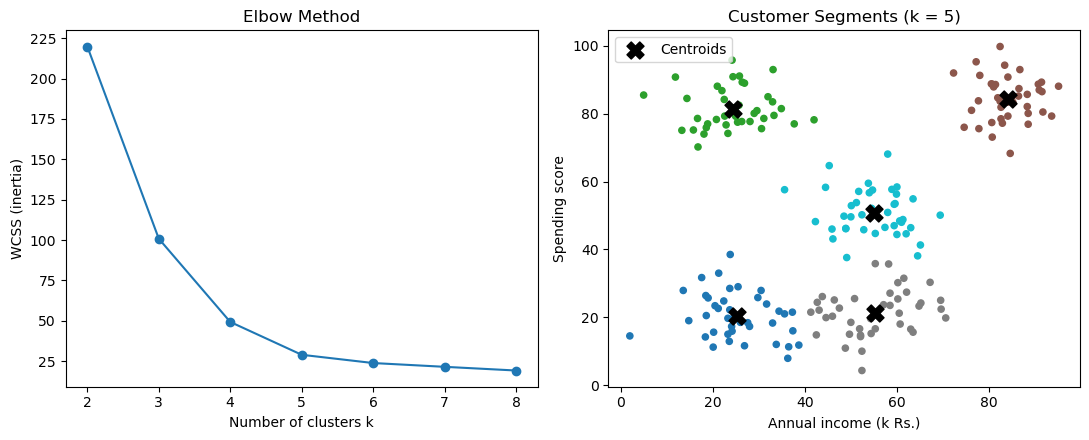

In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler 
from sklearn.metrics import silhouette_score 
  
np.random.seed(5) 
centres = [(25, 80), (55, 20), (85, 85), (55, 50), (25, 20)] 
rows = [] 
for i, (inc, score) in enumerate(centres): 
    for _ in range(40): 
        rows.append([np.random.normal(inc, 7), np.random.normal(score, 7)]) 
customers = pd.DataFrame( 
    np.round(rows, 1), columns=["annual_income_k", "spending_score"] 
) 
customers.insert(0, "customer_id", range(1, len(customers) + 1)) 
  
print("Mall Customer Segmentation using K-Means Clustering") 
print("=" * 52) 
print(customers.head().to_string(index=False)) 
print("Total customers:", len(customers)) 
  
X = StandardScaler().fit_transform( 
    customers[["annual_income_k", "spending_score"]] 
) 
  
# ---------- Choosing k: elbow (WCSS) and silhouette ---------- 
print("\n k     WCSS     Silhouette") 
wcss, sil = [], [] 
for k in range(2, 9): 
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X) 
    wcss.append(km.inertia_) 
    sil.append(silhouette_score(X, km.labels_)) 
    print(f"{k:>2}  {km.inertia_:>8.2f}   {sil[-1]:.4f}") 
best_k = range(2, 9)[int(np.argmax(sil))] 
print("\nBest k by silhouette score:", best_k) 
  
# ---------- Final model ---------- 
km = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(X) 
customers["cluster"] = km.labels_ 
profile = ( 
    customers.groupby("cluster")[["annual_income_k", "spending_score"]] 
    .mean() 
    .round(1) 
) 
profile["size"] = customers["cluster"].value_counts().sort_index() 
  
  
def describe(row): 
    inc = ( 
        "High income" 
        if row.annual_income_k > 70 
        else "Low income" if row.annual_income_k < 40 else "Mid income" 
    ) 
    sp = ( 
        "high spender" 
        if row.spending_score > 65 
        else "low spender" if row.spending_score < 35 else "average spender" 
    ) 
    return f"{inc}, {sp}" 
  
  
profile["segment"] = profile.apply(describe, axis=1) 
print("\nCluster profiles:") 
print(profile.to_string()) 
  
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5)) 
ax[0].plot(range(2, 9), wcss, "o-") 
ax[0].set_xlabel("Number of clusters k") 
ax[0].set_ylabel("WCSS (inertia)") 
ax[0].set_title("Elbow Method") 
sc = ax[1].scatter( 
    customers["annual_income_k"], 
    customers["spending_score"], 
    c=customers["cluster"], 
    cmap="tab10", 
    s=20, 
) 
centres = customers.groupby("cluster")[ 
    ["annual_income_k", "spending_score"] 
].mean() 
ax[1].scatter( 
    centres.iloc[:, 0], 
    centres.iloc[:, 1], 
    c="black", 
    marker="X", 
    s=150, 
    label="Centroids", 
) 
ax[1].set_xlabel("Annual income (k Rs.)") 
ax[1].set_ylabel("Spending score") 
ax[1].set_title(f"Customer Segments (k = {best_k})") 
ax[1].legend() 
plt.tight_layout() 
plt.savefig("exp08_kmeans.png", dpi=150) 
plt.show() 